## **Setup**

In [1]:
import cv2
import numpy as np
import matplotlib.pyplot as plt

# Interactive widgets (sliders, dropdowns, buttons ...)
import ipywidgets as widgets
from ipywidgets import (interact, interactive_output, fixed,
                        IntSlider, FloatSlider, IntRangeSlider,
                        Dropdown, Checkbox)
from IPython.display import display, clear_output



# Google Colab needs this line to display ipywidgets correctly (ignored elsewhere)
try:
    from google.colab import output
    output.enable_custom_widget_manager()
    IN_COLAB = True
except Exception:
    IN_COLAB = False

%matplotlib inline
plt.rcParams["figure.dpi"] = 100
plt.rcParams["axes.titlesize"] = 11

print("OpenCV :", cv2.__version__)
print("NumPy  :", np.__version__)
print("Running in Colab:", IN_COLAB)

OpenCV : 5.0.0
NumPy  : 2.1.3
Running in Colab: True


In [2]:
# ---------------------------------------------------------------
# IMAGE FACTORY  (no need to study this cell)
# ---------------------------------------------------------------
def make_scene(w=960, h=540):
    img = np.zeros((h, w, 3), np.uint8)
    horizon = int(h * 0.62)


    # Sky: vertical gradient (BGR colours)
    top, bot = np.array([200, 120, 40], np.float32), np.array([250, 225, 175], np.float32)
    t = np.linspace(0, 1, horizon, dtype=np.float32)[:, None, None]
    img[:horizon] = (top * (1 - t) + bot * t).astype(np.uint8)


    # Ground + hills
    img[horizon:] = (60, 140, 70)
    cv2.ellipse(img, (int(w*0.25), horizon), (int(w*0.30), 90), 0, 180, 360, (70, 120, 60), -1)
    cv2.ellipse(img, (int(w*0.75), horizon), (int(w*0.28), 70), 0, 180, 360, (80, 150, 85), -1)
    cv2.rectangle(img, (0, int(h*0.86)), (w, h), (50, 115, 60), -1)


    # Sun and clouds
    cv2.circle(img, (780, 110), 45, (60, 220, 255), -1)
    for cx, cy in [(480, 90), (540, 100), (600, 85)]:
        cv2.ellipse(img, (cx, cy), (45, 22), 0, 0, 360, (255, 255, 255), -1)

    # House
    cv2.rectangle(img, (200, 300), (400, 460), (120, 170, 235), -1)
    cv2.fillPoly(img, [np.array([(170, 300), (430, 300), (300, 200)])], (40, 50, 190))
    cv2.rectangle(img, (275, 370), (325, 460), (40, 70, 110), -1)
    cv2.rectangle(img, (220, 330), (260, 370), (255, 240, 200), -1)
    cv2.rectangle(img, (340, 330), (380, 370), (255, 240, 200), -1)

    # Tree
    cv2.rectangle(img, (610, 380), (630, 460), (30, 60, 100), -1)
    cv2.circle(img, (620, 350), 55, (40, 110, 40), -1)


    # Orientation helpers: big "F" and four coloured corner markers
    cv2.putText(img, "F", (40, 150), cv2.FONT_HERSHEY_DUPLEX, 4, (255, 255, 255), 9, cv2.LINE_AA)
    cv2.putText(img, "Lab 2", (w-190, h-25), cv2.FONT_HERSHEY_SIMPLEX, 1.2, (255, 255, 255), 3, cv2.LINE_AA)
    s = 36
    cv2.rectangle(img, (0, 0), (s, s), (0, 0, 255), -1)           # top-left     = RED
    cv2.rectangle(img, (w-s, 0), (w, s), (0, 200, 0), -1)         # top-right    = GREEN
    cv2.rectangle(img, (w-s, h-s), (w, h), (255, 0, 0), -1)       # bottom-right = BLUE
    cv2.rectangle(img, (0, h-s), (s, h), (0, 255, 255), -1)       # bottom-left  = YELLOW
    return img



scene   = make_scene()
gray    = cv2.cvtColor(scene, cv2.COLOR_BGR2GRAY)

# A few known positions in `scene` (x, y, ...) that we will use in exercises
LANDMARKS = {"sun": (780, 110, 45), "house": (170, 200, 430, 460), "tree": (565, 295, 675, 460)}

In [3]:
base = cv2.resize(scene, (480, 270), interpolation=cv2.INTER_AREA)    # half-size image keeps widgets fast
h, w = base.shape[:2]

In [4]:
def show_row(images, titles=None, figsize=None, axis=True, vmax=255):
    """Show several images side by side & BGR images are converted to RGB for display"""
    n = len(images)
    figsize = figsize or (4.6 * n, 3.6)
    fig, axs = plt.subplots(1, n, figsize=figsize)
    axs = np.atleast_1d(axs)

    for i, (ax, im) in enumerate(zip(axs, images)):
        if im.ndim == 2:
            ax.imshow(im, cmap="gray", vmin=0, vmax=vmax, interpolation="nearest")
        else:
            ax.imshow(cv2.cvtColor(im, cv2.COLOR_BGR2RGB), interpolation="nearest")
        if titles:
            ax.set_title(titles[i])
        if not axis:
            ax.axis("off")

    plt.tight_layout()
    plt.show()

# PART 10 — Scaling

### What is the problem?
In Part 3 we resized to a **new image size** but Scaling asks a slightly different question: *how do I stretch or shrink the picture content as a geometric transformation so it can be combined with rotation and translation?*

###  Why is this important?
Objects look bigger when they are close to the camera smaller when far

Scale changes also model zoom lenses

Many algorithms must work for **any scale**

### 👀 Visual intuition
```text
scale > 1  →  enlarge     (pixels move AWAY from the pivot)
scale < 1  →  shrink      (pixels move TOWARD the pivot)
scale = 1  →  same size
```

### Mathematical intuition

$$x' = s_x \cdot x \qquad y' = s_y \cdot y \qquad\Longleftrightarrow\qquad M=\begin{bmatrix} s_x & 0 & 0 \\ 0 & s_y & 0 \end{bmatrix}$$

If `sx ≠ sy` the picture is stretched (aspect ratio changes)

Scaling with this matrix grows/shrinks the image around the **origin (top-left corner)**

If we want the picture to grow around its **centre** we add a shift to keep the centre in place



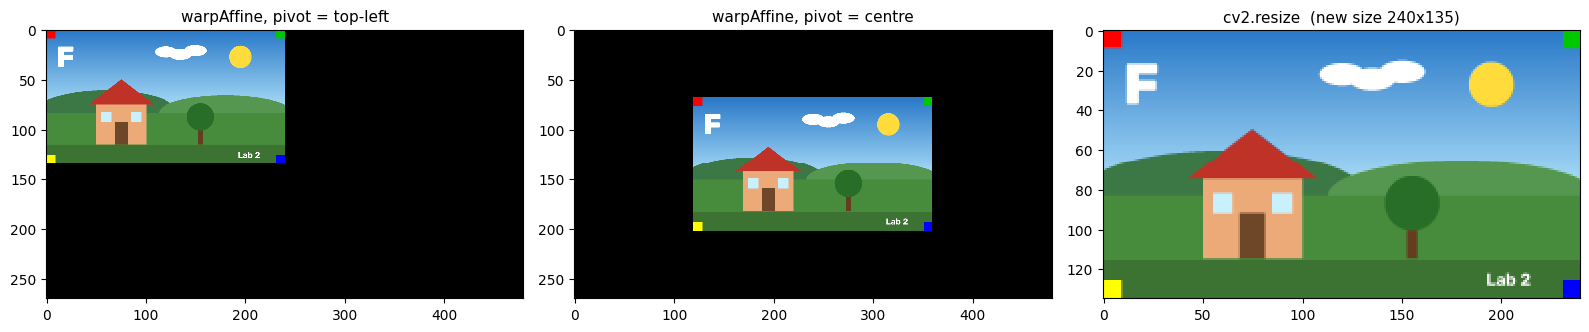

In [5]:
h, w = base.shape[:2]
sx, sy = 0.5, 0.5

M_origin = np.float32([[sx, 0, 0],
                       [0, sy, 0]])                          # scale around the top-left corner

cx, cy = w / 2, h / 2
M_center = np.float32([[sx, 0, cx - sx * cx],                # scale around the image centre:
                       [0, sy, cy - sy * cy]])               # add a shift to keep the centre fixed

a = cv2.warpAffine(base, M_origin, (w, h), flags=cv2.INTER_LINEAR)
b = cv2.warpAffine(base, M_center, (w, h), flags=cv2.INTER_LINEAR)
c = cv2.resize(base, None, fx=sx, fy=sy, interpolation=cv2.INTER_AREA)

show_row([a, b, c],
         ["warpAffine, pivot = top-left", "warpAffine, pivot = centre", f"cv2.resize  (new size {c.shape[1]}x{c.shape[0]})"],
         figsize=(16, 3.4))

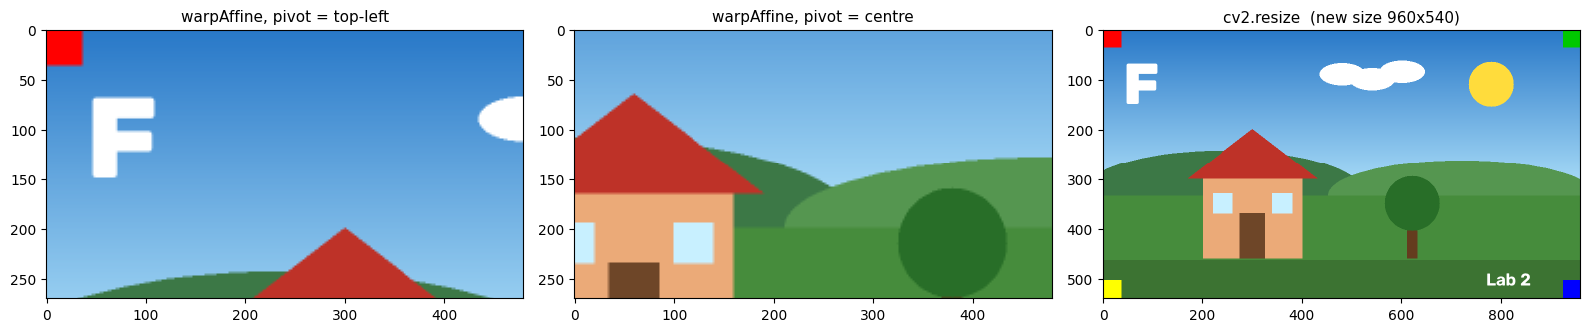

In [6]:
h, w = base.shape[:2]
sx, sy = 2, 2

M_origin = np.float32([[sx, 0, 0],
                       [0, sy, 0]])                          # scale around the top-left corner

cx, cy = w / 2, h / 2
M_center = np.float32([[sx, 0, cx - sx * cx],                # scale around the image centre:
                       [0, sy, cy - sy * cy]])               # add a shift to keep the centre fixed

a = cv2.warpAffine(base, M_origin, (w, h), flags=cv2.INTER_LINEAR)
b = cv2.warpAffine(base, M_center, (w, h), flags=cv2.INTER_LINEAR)
c = cv2.resize(base, None, fx=sx, fy=sy, interpolation=cv2.INTER_AREA)

show_row([a, b, c],
         ["warpAffine, pivot = top-left", "warpAffine, pivot = centre", f"cv2.resize  (new size {c.shape[1]}x{c.shape[0]})"],
         figsize=(16, 3.4))

###  What happened?
* In the first image the picture shrank **toward the top-left corner**
* In the second it shrank **toward the centre**
* `cv2.resize` produced a **smaller image**



# PART 11 — Affine Transformation

### What is the problem?
So far we learned translation, rotation and scaling separately But what if we want **several at once** plus **shearing** (slanting, like italic text)?

An **affine transformation** is a single 2×3 matrix that can represent any combination of:
* Translation · Rotation · Scaling · Shearing

$$\begin{bmatrix} x' \\ y' \end{bmatrix} = \begin{bmatrix} a & b & t_x \\ c & d & t_y \end{bmatrix}\begin{bmatrix} x \\ y \\ 1 \end{bmatrix}$$

###  Why is this important?
Everything from Parts 8–10 is a special case of this single formula

Most image-alignment algorithms estimate an affine matrix.


### Code
```python
M = cv2.getAffineTransform(src_points, dst_points)    # 3 points each, float32
result = cv2.warpAffine(img, M, (w, h))
```

Affine matrix M =
 [[ 6.68e-01  1.49e-01  6.00e+01]
 [-4.20e-02  7.06e-01  4.00e+01]]


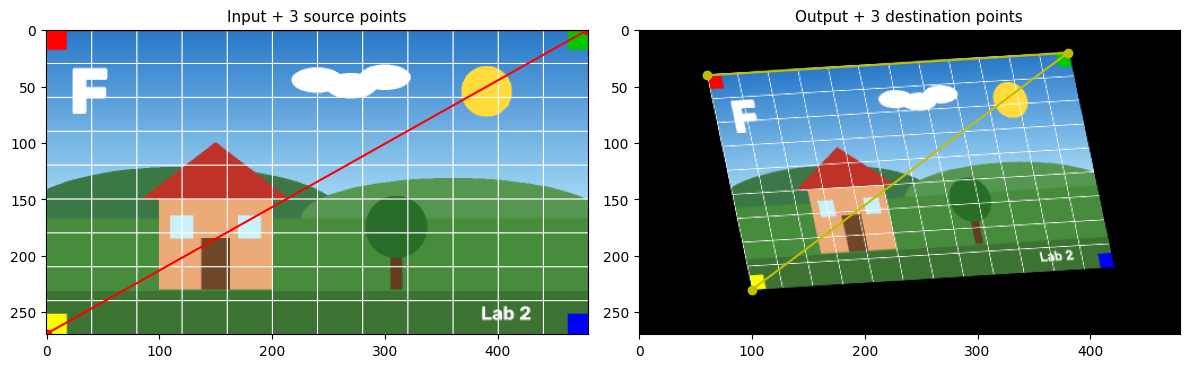

In [7]:
# A grid helps us see geometry: straight lines + right angles
grid_img = base.copy()
h, w = grid_img.shape[:2]

for x in range(0, w, 40): cv2.line(grid_img, (x, 0), (x, h), (255, 255, 255), 1)
for y in range(0, h, 30): cv2.line(grid_img, (0, y), (w, y), (255, 255, 255), 1)


# Three points in the INPUT image: top-left, top-right, bottom-left
src = np.float32([[0, 0], [w - 1, 0], [0, h - 1]])

# Where should they go in the OUTPUT image?
dst = np.float32([[60, 40], [w - 100, 20], [100, h - 40]])

M = cv2.getAffineTransform(src, dst)
print("Affine matrix M =\n", M.round(3))
result = cv2.warpAffine(grid_img, M, (w, h))

fig, axs = plt.subplots(1, 2, figsize=(12, 3.8))
axs[0].imshow(cv2.cvtColor(grid_img, cv2.COLOR_BGR2RGB)); axs[0].plot(*src.T, "ro-"); axs[0].set_title("Input + 3 source points")
axs[1].imshow(cv2.cvtColor(result, cv2.COLOR_BGR2RGB));   axs[1].plot(*dst.T, "yo-"); axs[1].set_title("Output + 3 destination points")
plt.tight_layout(); plt.show()

### What happened?
* `src` and `dst` are 3×2 `float32` arrays — OpenCV is strict about `float32`
* `getAffineTransform` solved the 6 unknowns and returned the 2×3 matrix `M`
* `warpAffine` applied `M` to the whole image. Look at the grid: **lines are still straight and parallel** but the right angles were not preserved



In [8]:
def affine_lab(preset="Custom (use sliders)",
               p0x=0, p0y=0, p1x=479, p1y=0, p2x=0, p2y=269):
    h, w = grid_img.shape[:2]
    src = np.float32([[0, 0], [w - 1, 0], [0, h - 1]])
    if preset == "Identity":
        dst = src.copy()
    elif preset == "Translate (+80, +40)":
        dst = src + np.float32([80, 40])
    elif preset == "Rotate 20°":
        Mr = cv2.getRotationMatrix2D((w / 2, h / 2), 20, 0.8)
        dst = cv2.transform(src[None], Mr)[0]
    elif preset == "Scale 0.6":
        dst = src * 0.6 + np.float32([w * 0.2, h * 0.2])
    elif preset == "Shear (slant right)":
        dst = np.float32([[0, 0], [w - 1, 0], [0.5 * (h - 1), h - 1]]) * np.float32([0.8, 1]) + np.float32([0, 0])
    else:
        dst = np.float32([[p0x, p0y], [p1x, p1y], [p2x, p2y]])

    v1, v2 = dst[1] - dst[0], dst[2] - dst[0]
    cross = v1[0] * v2[1] - v1[1] * v2[0]
    if abs(cross) < 1e-3:
        print("⚠️ The 3 points are on one line — no valid affine transformation exists.")
        return
    M = cv2.getAffineTransform(src, dst)
    out = cv2.warpAffine(grid_img, M, (w, h))

    angle = np.degrees(np.arccos(np.dot(v1, v2) / (np.linalg.norm(v1) * np.linalg.norm(v2))))
    area_factor = abs(np.linalg.det(M[:, :2]))

    fig, axs = plt.subplots(1, 2, figsize=(12, 3.8))
    axs[0].imshow(cv2.cvtColor(grid_img, cv2.COLOR_BGR2RGB)); axs[0].plot(*src.T, "ro-", ms=8); axs[0].set_title("Input")
    axs[1].imshow(cv2.cvtColor(out, cv2.COLOR_BGR2RGB)); axs[1].plot(*dst.T, "yo-", ms=8); axs[1].set_title("Output")
    axs[1].set_xlim(0, w); axs[1].set_ylim(h, 0)
    plt.tight_layout(); plt.show()
    print("M =", M.round(3).tolist())
    print(f"✅ Straight lines & parallel lines are preserved.")
    print(f"❌ Angle at P0: 90° → {angle:.1f}°      ❌ Area scaled by {area_factor:.2f}×")

presets = ["Custom (use sliders)", "Identity", "Translate (+80, +40)", "Rotate 20°", "Scale 0.6", "Shear (slant right)"]
interact(affine_lab,
         preset=Dropdown(options=presets, value="Shear (slant right)", description="Preset"),
         p0x=IntSlider(min=-100, max=580, step=10, value=0, description="P0 x"),
         p0y=IntSlider(min=-100, max=370, step=10, value=0, description="P0 y"),
         p1x=IntSlider(min=-100, max=580, step=10, value=479, description="P1 x"),
         p1y=IntSlider(min=-100, max=370, step=10, value=0, description="P1 y"),
         p2x=IntSlider(min=-100, max=580, step=10, value=0, description="P2 x"),
         p2y=IntSlider(min=-100, max=370, step=10, value=269, description="P2 y"));

interactive(children=(Dropdown(description='Preset', index=5, options=('Custom (use sliders)', 'Identity', 'Tr…

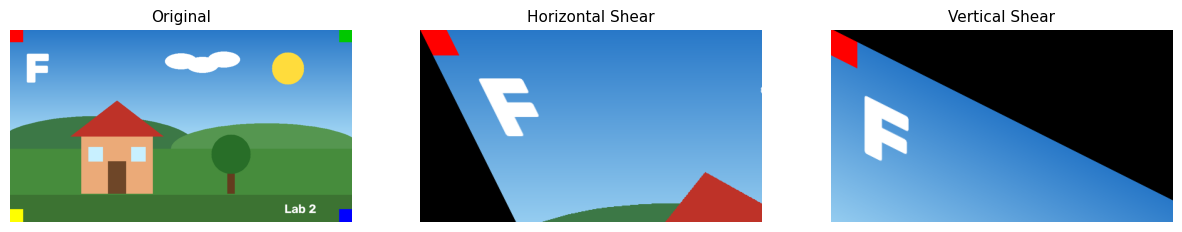

In [9]:
img = scene
h, w = base.shape[:2]

# Shear strength
kx = 0.5   # horizontal shear
ky = 0.5   # vertical shear




# -----------------------------
# 1. Horizontal Shear
# -----------------------------
M_horizontal = np.float32([
    [1, kx, 0],
    [0, 1,  0]
])

horizontal = cv2.warpAffine(
    img,
    M_horizontal,
    (w, h)
)



# -----------------------------
# 2. Vertical Shear
# -----------------------------
M_vertical = np.float32([
    [1, 0,  0],
    [ky, 1, 0]
])

vertical = cv2.warpAffine(
    img,
    M_vertical,
    (w, h)
)

# -----------------------------
# Visualization
# -----------------------------
plt.figure(figsize=(15, 5))

plt.subplot(1, 3, 1)
plt.imshow(cv2.cvtColor(img, cv2.COLOR_BGR2RGB))
plt.title("Original")
plt.axis("off")

plt.subplot(1, 3, 2)
plt.imshow(cv2.cvtColor(horizontal, cv2.COLOR_BGR2RGB))
plt.title("Horizontal Shear")
plt.axis("off")

plt.subplot(1, 3, 3)
plt.imshow(cv2.cvtColor(vertical, cv2.COLOR_BGR2RGB))
plt.title("Vertical Shear")
plt.axis("off")

plt.show()


#  PART 12 — Image Arithmetic

### What is the problem?
> "I want to make an image brighter or find what changed between two photos Can I just add or subtract images?"

An image is an array of numbers so we can **add, subtract, multiply** images pixel by pixel. But there is a trap: pixels are stored as `uint8` (0–255) What happens at `200 + 100`?

### Why is this important?
Brightness change
image differences (motion/change detection)
blending and many deep-learning pre-processing steps are image arithmetic Wrong overflow handling creates bizarre artifacts

### Real-world application
Security cameras compare today's frame with a reference frame (subtraction) Photo apps brighten pictures (addition)


In [10]:
a = np.array([200, 250, 10], dtype=np.uint8)
b = np.array([100,  10, 20], dtype=np.uint8)

print("NumPy  a + b       :", a + b)                 # wraps around   200+100=300 -> 300-256 = 44
print("OpenCV cv2.add     :", cv2.add(a, b).ravel()) # saturates at 255
print()
print("NumPy  b - a       :", b - a)                 # negative numbers wrap to large values
print("OpenCV cv2.subtract:", cv2.subtract(b, a).ravel())   # saturates at 0

NumPy  a + b       : [44  4 30]
OpenCV cv2.add     : [300. 260.  30.   0.]

NumPy  b - a       : [156  16  10]
OpenCV cv2.subtract: [-100. -240.   10.    0.]


**NumPy Addition (Modulo Arithmetic):**

 When adding values that exceed the maximum limit (like 255 for 8-bit images), NumPy wraps the value around. For example, $200 + 100 = 300$, which wraps to $44$ ($300 - 256$).  


**OpenCV Addition (Saturation Arithmetic):**

 When using cv2.add, values that exceed the maximum limit do not wrap around; instead, they saturate (cap) at the maximum value of $255$.


**NumPy Subtraction:**

 If a subtraction results in a negative number, NumPy wraps it around to a large positive value.

 Ex: If you subtract 100 from 50 (i.e., 50 - 100), the true mathematical result is -50. Because -50 is outside the 0–255 range, NumPy calculates this as -50 % 256, which wraps around to 206.

**OpenCV Subtraction:**

 When using cv2.subtract, results that fall below zero are saturated (capped) at $0$.

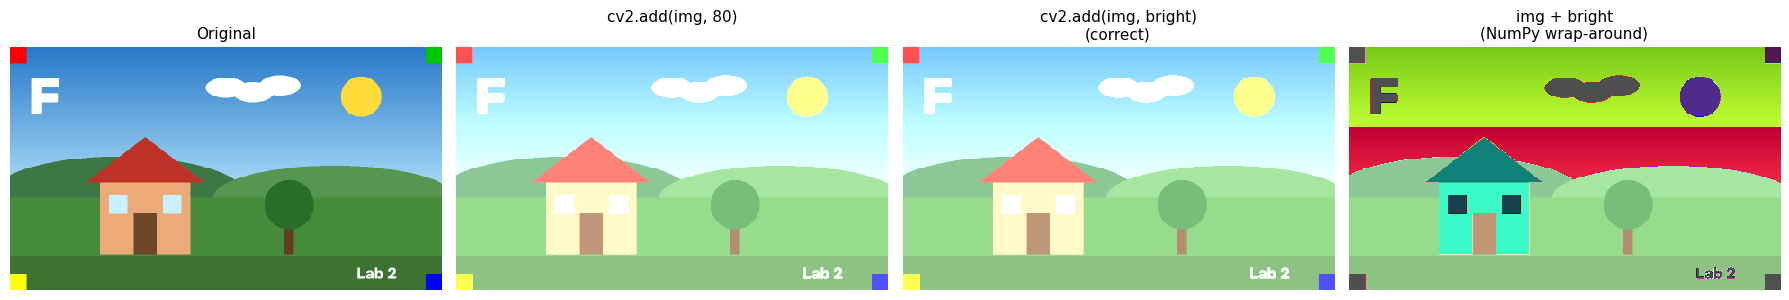

In [11]:
img = base                                              # 480 x 270 half-size scene
bright = np.full_like(img, 80)                          # an image of the same shape filled with 80

wrong_scalar = cv2.add(img, 80)                         # increases the brightness of the entire image by adding 80 to the intensity value of every pixel
good_cv      = cv2.add(img, bright)                     # +80 on all 3 channels, saturating
bad_numpy    = img + bright                             # wraps around: bright areas turn dark

show_row([img, wrong_scalar, good_cv, bad_numpy],
         ["Original", "cv2.add(img, 80)\n", "cv2.add(img, bright)\n(correct)", "img + bright\n(NumPy wrap-around)"],
         figsize=(18, 3.4), axis=False)

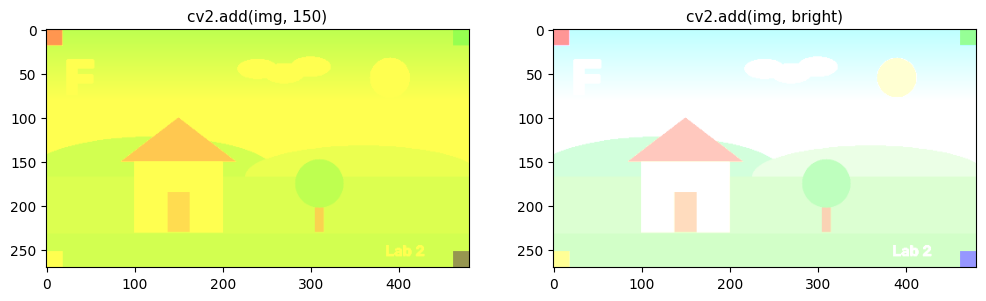

In [12]:
wrong = cv2.add(img, 150)
wrong[:, :, 0] = 80

bright = np.full_like(img, 150)
correct = cv2.add(img, bright)


plt.figure(figsize=(12, 5))
plt.subplot(1, 2, 1)
plt.imshow(cv2.cvtColor(wrong, cv2.COLOR_BGR2RGB))
plt.title("cv2.add(img, 150)")

plt.subplot(1, 2, 2)
plt.imshow(cv2.cvtColor(correct, cv2.COLOR_BGR2RGB))
plt.title("cv2.add(img, bright)")

plt.show()

### 🎮 Interactive Experiment — NumPy vs OpenCV
Increase the value being added Watch the bright regions (clouds, sun, house walls) in the NumPy result they **wrap around** to dark and create speckle artifacts

In [13]:
def arithmetic_lab(value=80, operation="add"):
    layer = np.full_like(base, value)
    if operation == "add":
        np_res = base + layer
        cv_res = cv2.add(base, layer)
    else:
        np_res = base - layer
        cv_res = cv2.subtract(base, layer)
    n_wrapped = int(np.sum(np_res != cv_res) / 3)
    show_row([base, np_res, cv_res],
             ["Original", f"NumPy  img {'+' if operation=='add' else '-'} {value}  (wraps)", f"OpenCV {operation}  (clips)"],
             figsize=(16, 3.4), axis=False)
    print(f"Pixels that differ between NumPy and OpenCV: {n_wrapped:,}  ({100*n_wrapped/(base.shape[0]*base.shape[1]):.1f} % of the image)")

interact(arithmetic_lab,
         value=IntSlider(min=0, max=255, step=5, value=80, description="Value"),
         operation=Dropdown(options=["add", "subtract"], value="add", description="Operation"));

interactive(children=(IntSlider(value=80, description='Value', max=255, step=5), Dropdown(description='Operati…

# PART 13 — Bitwise Operations

### What is the problem?
> "I want to keep only the pixels inside a circle and make everything else black Addition and blending don't do that"

### 👀 Visual intuition
Each `uint8` pixel is 8 bits Black = `00000000` (all zeros) and white = `11111111` (all ones)

For black/white masks every pixel is simply **0 (false)** or **255 (true)**

| A | B | AND | OR | XOR | NOT A |
|:-:|:-:|:-:|:-:|:-:|:-:|
| 0 | 0 | 0 | 0 | 0 | 1 |
| 0 | 1 | 0 | 1 | 1 | 1 |
| 1 | 0 | 0 | 1 | 1 | 0 |
| 1 | 1 | **1** | 1 | **0** | 0 |

* **AND** → pixel is white only where **both** are white (intersection)
* **OR** → white where **either** is white (union)
* **XOR** → white where **exactly one** is white
* **NOT** → swaps white and black (inverts)

```text
Image  +  Mask   →   Selected region
```

In [14]:
x, y = 200, 100
print(f"{x:3d} = {x:08b}")
print(f"{y:3d} = {y:08b}")
print(f"AND    = {x & y:08b}  = {x & y}")
print(f"OR     = {x | y:08b}  = {x | y}")
print(f"XOR    = {x ^ y:08b}  = {x ^ y}")
print(f"NOT(x) = {(~x) & 255:08b}  = {(~x) & 255}")
print()
print("A white pixel (255) AND any value keeps the value:", 255 & 173)
print("A black pixel (0)   AND any value gives zero      :", 0 & 173)

200 = 11001000
100 = 01100100
AND    = 01000000  = 64
OR     = 11101100  = 236
XOR    = 10101100  = 172
NOT(x) = 00110111  = 55

A white pixel (255) AND any value keeps the value: 173
A black pixel (0)   AND any value gives zero      : 0


### 🔎 What happened?
`255 = 11111111` so `255 AND x = x` → **white keeps the pixel** `0 AND x = 0` → **black deletes it** That is exactly why a black-and-white mask can select parts of an image

### 💻 Code
```python
cv2.bitwise_and(A, B)     cv2.bitwise_or(A, B)     cv2.bitwise_xor(A, B)     cv2.bitwise_not(A)
```
We create two simple black/white shapes and combine them:

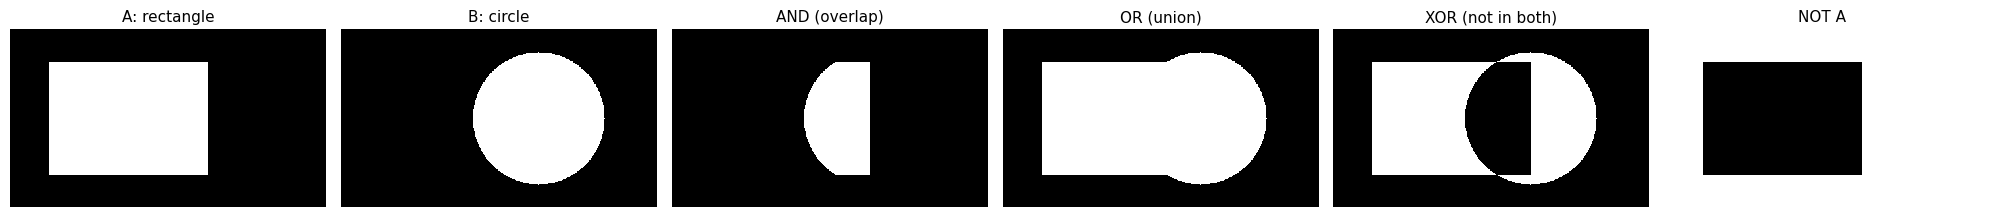

In [15]:
H_, W_ = 270, 480
rect_mask   = np.zeros((H_, W_), np.uint8);  cv2.rectangle(rect_mask, (60, 50), (300, 220), 255, -1)
circle_mask = np.zeros((H_, W_), np.uint8);  cv2.circle(circle_mask, (300, 135), 100, 255, -1)

b_and = cv2.bitwise_and(rect_mask, circle_mask)
b_or  = cv2.bitwise_or(rect_mask, circle_mask)
b_xor = cv2.bitwise_xor(rect_mask, circle_mask)
b_not = cv2.bitwise_not(rect_mask)

show_row([rect_mask, circle_mask, b_and, b_or, b_xor, b_not],
         ["A: rectangle", "B: circle", "AND (overlap)", "OR (union)", "XOR (not in both)", "NOT A"],
         figsize=(20, 2.4), axis=False)

### 🎮 Interactive Experiment — Bitwise lab
Choose an operation and slide the circle across the rectangle. The last panel applies the result as a **mask** on the image: only white pixels of the mask survive.

In [16]:
def bitwise_lab(op="AND", circle_x=300, radius=100):
    A_ = rect_mask
    B_ = np.zeros((H_, W_), np.uint8); cv2.circle(B_, (circle_x, 135), radius, 255, -1)
    ops = {"AND": cv2.bitwise_and, "OR": cv2.bitwise_or, "XOR": cv2.bitwise_xor}
    res = cv2.bitwise_not(A_) if op == "NOT A" else ops[op](A_, B_)
    selected = cv2.bitwise_and(base, base, mask=res)               # image + mask → selected region
    show_row([A_, B_, res, selected], ["A: rectangle", "B: circle", f"Result: {op}", "Image kept where result is white"],
             figsize=(18, 2.8), axis=False)

interact(bitwise_lab,
         op=Dropdown(options=["AND", "OR", "XOR", "NOT A"], value="AND", description="Operation"),
         circle_x=IntSlider(min=0, max=480, step=10, value=300, description="Circle x"),
         radius=IntSlider(min=20, max=180, step=10, value=100, description="Radius"));

interactive(children=(Dropdown(description='Operation', options=('AND', 'OR', 'XOR', 'NOT A'), value='AND'), I…

# PART 14 — Image Masking

### What is the problem?
> **A mask tells the computer which pixels to keep and which pixels to ignore**

* A mask is a **single-channel `uint8` image** with the same height and width as the image
* **255 (white)** = "use this pixel", **0 (black)** = "ignore this pixel"

### Why is this important?
Masks let us process **only the interesting part** of an image: ignore the sky, the car's hood the background or everything outside a lane

### Real-world application
Self-driving cars mask the road area

Photo editors cut out people

Medical imaging masks an organ

Video calls blur/replace the background

### 👀 Visual intuition
```text
 Original   +   Mask   →   Masked result
 (all pixels)   (white=keep, black=ignore)   (only white area visible)
```

### Code
```python
mask = np.zeros(img.shape[:2], dtype=np.uint8)       # start with ALL black (ignore everything)
cv2.circle(mask, (cx, cy), radius, 255, -1)          # draw a filled WHITE circle (keep this)
result = cv2.bitwise_and(img, img, mask=mask)        # keep only pixels where mask != 0
```

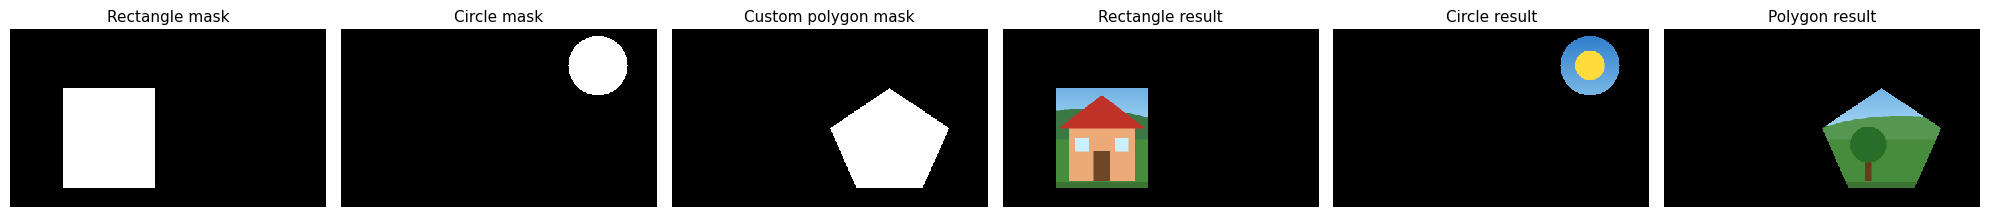

mask shape: (270, 480) | dtype: uint8 | unique values: [  0 255]


In [17]:
img = base
h, w = img.shape[:2]

# 1) Rectangle mask
rect_m = np.zeros((h, w), np.uint8)
cv2.rectangle(rect_m, (80, 90), (220, 240), 255, -1)           # -1 = filled

# 2) Circle mask
circ_m = np.zeros((h, w), np.uint8)
cv2.circle(circ_m, (390, 55), 45, 255, -1)

# 3) Custom (polygon) mask: any shape from a list of points
poly_m = np.zeros((h, w), np.uint8)
pts = np.array([(240, 150), (330, 90), (420, 150), (380, 240), (280, 240)], np.int32)
cv2.fillPoly(poly_m, [pts], 255)

masks = [rect_m, circ_m, poly_m]
results = [cv2.bitwise_and(img, img, mask=m) for m in masks]

show_row([rect_m, circ_m, poly_m] + results,
         ["Rectangle mask", "Circle mask", "Custom polygon mask", "Rectangle result", "Circle result", "Polygon result"],
         figsize=(20, 2.5), axis=False)
print("mask shape:", rect_m.shape, "| dtype:", rect_m.dtype, "| unique values:", np.unique(rect_m))

###  What happened? (line by line)
| Code | Meaning |
|---|---|
| `np.zeros((h, w), np.uint8)` | A black 2-D image, same height & width as `img`, one channel |
| `cv2.rectangle / circle / fillPoly(..., 255, -1)` | Drawing functions from Lab 1, now used to draw **white** shapes on the mask |
| `cv2.bitwise_and(img, img, mask=mask)` | AND the image with itself but **only at pixels where `mask` ≠ 0**; all other output pixels become 0 |
| `np.unique(mask)` | Shows the mask only contains 0 and 255 |

**Useful extras:**
* **Inverse mask** `cv2.bitwise_not(mask)` selects everything *outside* the shape
* **Keep one, replace the rest:** `foreground = and(img, mask)`, `background = and(other, not(mask))` then add them


In [18]:
import ast

def mask_editor(shape="circle", cx=240, cy=135, size=80, invert=False, background="black",
                polygon="[(100,60),(400,40),(450,200),(250,250),(60,180)]"):
    h, w = base.shape[:2]
    mask = np.zeros((h, w), np.uint8)
    if shape == "rectangle":
        cv2.rectangle(mask, (cx - size, cy - size // 2), (cx + size, cy + size // 2), 255, -1)
    elif shape == "circle":
        cv2.circle(mask, (cx, cy), size, 255, -1)
    elif shape == "ellipse":
        cv2.ellipse(mask, (cx, cy), (size, size // 2), 0, 0, 360, 255, -1)
    elif shape == "triangle":
        cv2.fillPoly(mask, [np.array([(cx, cy - size), (cx - size, cy + size), (cx + size, cy + size)], np.int32)], 255)
    elif shape == "ring":
        cv2.circle(mask, (cx, cy), size, 255, -1)
        cv2.circle(mask, (cx, cy), size // 2, 0, -1)
    elif shape == "custom polygon":
        try:
            pts = np.array(ast.literal_eval(polygon), np.int32)
            cv2.fillPoly(mask, [pts], 255)
        except Exception as e:
            print("⚠️ Could not read the polygon. Example: [(100,60),(400,40),(450,200)]")
    if invert:
        mask = cv2.bitwise_not(mask)

    inside = cv2.bitwise_and(base, base, mask=mask)                     # pixels we keep
    if background == "black":
        result = inside
    else:
        other = B if background == "pattern" else np.full_like(base, 255)
        outside = cv2.bitwise_and(other, other, mask=cv2.bitwise_not(mask))
        result = cv2.add(inside, outside)                                # combine the two parts
    kept = 100 * np.count_nonzero(mask) / mask.size
    show_row([base, mask, result], ["Original", "Mask (white = keep)", f"Masked result ({kept:.0f}% of pixels kept)"],
             figsize=(15, 3.5), axis=False)

interact(mask_editor,
         shape=Dropdown(options=["circle", "rectangle", "ellipse", "triangle", "ring", "custom polygon"], value="circle", description="Shape"),
         cx=IntSlider(min=0, max=480, step=10, value=240, description="Centre x"),
         cy=IntSlider(min=0, max=270, step=10, value=135, description="Centre y"),
         size=IntSlider(min=10, max=200, step=10, value=80, description="Size"),
         invert=Checkbox(value=False, description="Invert mask"),
         background=Dropdown(options=["black", "pattern", "white"], value="black", description="Outside"),
         polygon=widgets.Text(value="[(100,60),(400,40),(450,200),(250,250),(60,180)]", description="Polygon", continuous_update=False));

interactive(children=(Dropdown(description='Shape', options=('circle', 'rectangle', 'ellipse', 'triangle', 'ri…

#  PART 15 — Brightness

### What is the problem?
> "The photo was taken at dusk and looks too dark. How can we make it brighter?"

Brightness means **how light or dark the image looks overall** To make it brighter we **add a constant** to every pixel:

$$\text{new_pixel} = \text{old_pixel} + \beta$$

* `β > 0` → brighter   but  `β < 0` → darker

###  Why is this important?
Lighting changes between cameras, rooms and times of day

###  Real-world application
Phone auto-brightness, correcting under-exposed photos, compensating for dark tunnels in self-driving datasets

###  What about values above 255 or below 0? — **Clipping**
```text
new < 0     →  0
new > 255   →  255
```
This is **information loss**: two different bright pixels (e.g. 240 and 250) can both become 255 and can never be told apart again

###  Code — safe version using a wider data type
To avoid `uint8` overflow compute in `int16`, clip then convert back:
```python
bright = np.clip(img.astype(np.int16) + beta, 0, 255).astype(np.uint8)
```

max before: 255   max of raw sum: 315   max after clip: 255


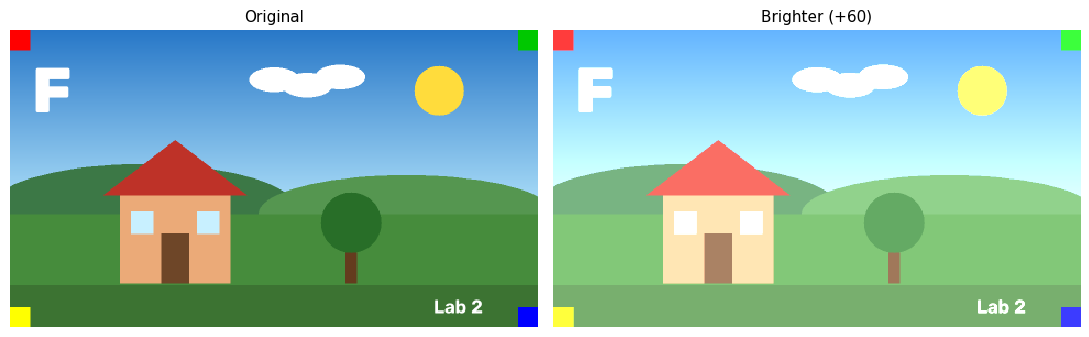

In [19]:
beta = 60
img16  = base.astype(np.int16)                         # step 1: wider type so 200+60 = 260 is allowed
summed = img16 + beta                                  # step 2: add beta to every value
clipped = np.clip(summed, 0, 255)                      # step 3: force the range 0..255
brighter = clipped.astype(np.uint8)                    # step 4: back to uint8 for display/saving

print("max before:", base.max(), "  max of raw sum:", summed.max(), "  max after clip:", brighter.max())
show_row([base, brighter], ["Original", f"Brighter (+{beta})"], figsize=(11, 3.4), axis=False)

### 🎮 Interactive Experiment — Brightness slider


In [20]:
def brightness_lab(beta=50):
    out = np.clip(base.astype(np.int16) + beta, 0, 255).astype(np.uint8)
    xs = np.arange(256)
    ys = np.clip(xs + beta, 0, 255)
    clipped_hi = 100 * np.mean(out == 255); clipped_lo = 100 * np.mean(out == 0)

    fig, axs = plt.subplots(1, 3, figsize=(16, 3.6), gridspec_kw={"width_ratios": [1, 1.4, 1.4]})
    axs[0].plot(xs, xs, "--", color="gray", label="no change"); axs[0].plot(xs, ys, color="tab:orange", lw=2, label=f"new = old + {beta}")
    axs[0].set_xlabel("old pixel"); axs[0].set_ylabel("new pixel"); axs[0].set_xlim(0, 255); axs[0].set_ylim(0, 255)
    if beta > 0: axs[0].axvspan(255 - beta, 255, color="red", alpha=0.15)
    if beta < 0: axs[0].axvspan(0, -beta, color="red", alpha=0.15)
    axs[0].legend(); axs[0].set_title("Transformation")
    axs[1].imshow(cv2.cvtColor(base, cv2.COLOR_BGR2RGB)); axs[1].set_title("Original"); axs[1].axis("off")
    axs[2].imshow(cv2.cvtColor(out, cv2.COLOR_BGR2RGB)); axs[2].axis("off")
    axs[2].set_title(f"β = {beta}   (255-clipped {clipped_hi:.1f}%, 0-clipped {clipped_lo:.1f}%)")
    plt.tight_layout(); plt.show()

interact(brightness_lab, beta=IntSlider(min=-100, max=100, step=5, value=50, description="β"));

interactive(children=(IntSlider(value=50, description='β', min=-100, step=5), Output()), _dom_classes=('widget…


#  PART 16 — Contrast

### What is the problem?
> "The photo looks flat and grey: the darks aren't dark and the lights aren't light"

**Contrast** is the *difference* between dark and bright areas To increase it we **multiply** pixel values:

$$\text{new_pixel} = \alpha \times \text{old_pixel}$$

* `α > 1` → higher contrast (values spread apart)
* `0 < α < 1` → lower contrast (values squeezed together)
* `α = 1` → no change

Multiplying also changes brightness (bright pixels move a lot, dark pixels hardly) so we usually combine both:

$$\text{new} = \alpha \times \text{old} + \beta$$

| Parameter | Controls | Typical range |
|---|---|---|
| `alpha` (gain) | contrast | 0.5 – 3.0 |
| `beta` (bias) | brightness | −100 – +100 |

### Real-world application
 making text on scanned pages easier to read.

### Code
```python
new = np.clip(alpha * img.astype(np.float32) + beta, 0, 255).astype(np.uint8)
```
> ⚠️ `cv2.convertScaleAbs(img, alpha, beta)` also exists, but it takes the **absolute value** of negative results (so a pixel at −30 becomes +30) For learning we use the explicit NumPy version

**Why is increasing contrast useful?**

Make details easier to see

Imagine a document where the text is gray and the background is light gray:

Background: 180
Text:       150

Difference = only 30.

Increasing contrast can make the text darker relative to the background, making it easier to read

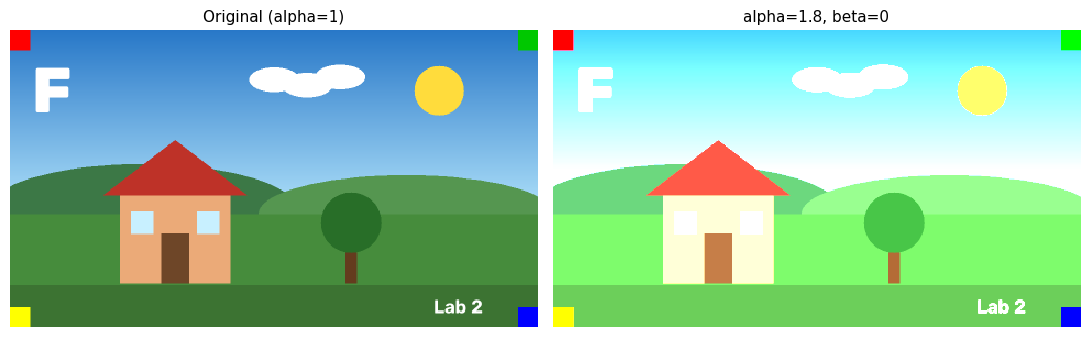

In [21]:
alpha, beta = 1.8, 0
new = alpha * base.astype(np.float32) + beta            # float math: no overflow worry
new = np.clip(new, 0, 255).astype(np.uint8)             # clip, then convert

show_row([base, new], ["Original (alpha=1)", f"alpha={alpha}, beta={beta}"], figsize=(11, 3.4), axis=False)

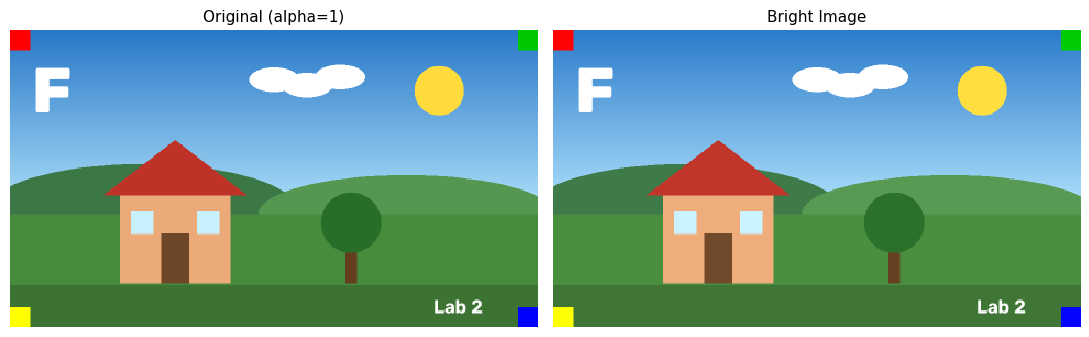

In [22]:
bright = cv2.convertScaleAbs(img, alpha=1, beta=3)
show_row([base, bright], ["Original (alpha=1)", "Bright Image"], figsize=(11, 3.4), axis=False)

### 🎮 Interactive Experiment — Contrast + brightness
Move `alpha` and `beta`. Tick **"pivot at 128"** to multiply around mid-grey instead of around 0: it raises contrast **without** making everything brighter: `new = α·(old − 128) + 128 + β`

In [23]:
def contrast_lab(alpha=1.5, beta=0, pivot=False):
    f = base.astype(np.float32)
    new = alpha * (f - 128) + 128 + beta if pivot else alpha * f + beta
    out = np.clip(new, 0, 255).astype(np.uint8)
    xs = np.arange(256, dtype=np.float32)
    ys = np.clip(alpha * (xs - 128) + 128 + beta if pivot else alpha * xs + beta, 0, 255)

    fig, axs = plt.subplots(1, 3, figsize=(16, 3.6), gridspec_kw={"width_ratios": [1, 1.4, 1.4]})
    axs[0].plot(xs, xs, "--", color="gray"); axs[0].plot(xs, ys, color="tab:orange", lw=2)
    axs[0].set_xlim(0, 255); axs[0].set_ylim(0, 255); axs[0].set_xlabel("old pixel"); axs[0].set_ylabel("new pixel")
    axs[0].set_title("Steeper line = more contrast")
    axs[1].imshow(cv2.cvtColor(base, cv2.COLOR_BGR2RGB)); axs[1].axis("off"); axs[1].set_title("Original")
    axs[2].imshow(cv2.cvtColor(out, cv2.COLOR_BGR2RGB)); axs[2].axis("off")
    axs[2].set_title(f"alpha={alpha}, beta={beta}{', pivot 128' if pivot else ''}   std {base.std():.0f} → {out.std():.0f}")
    plt.tight_layout(); plt.show()

interact(contrast_lab,
         alpha=widgets.FloatSlider(min=0.2, max=3.0, step=0.1, value=1.5, description="α (contrast)"),
         beta=IntSlider(min=-100, max=100, step=5, value=0, description="β (bright)"),
         pivot=Checkbox(value=False, description="Pivot at 128"));

interactive(children=(FloatSlider(value=1.5, description='α (contrast)', max=3.0, min=0.2), IntSlider(value=0,…


# PART 17 — Image Histograms

### What is the problem?
So far we always asked **"where are the pixels?"** (positions, shapes, regions)

> **Instead of looking at where pixel values are located what if we ask how pixel values are distributed?**

A **histogram** counts how many pixels have each intensity value (0 = black … 255 = white) It forgets *where* the pixels are and keeps only *how many of each brightness exist*

```text
x-axis → intensity (0 = black … 255 = white)
y-axis → number of pixels with that intensity
```

### Why is this important?
One glance at a histogram tells you if an image is too dark, too bright or has low contrast: without even looking at the picture

### Real-world application
Document scanners analyse histograms to separate ink from paper


### Code (grayscale)
```python
hist = cv2.calcHist([image], [channel], mask, [bins], [range_min, range_max])
```

hist shape: (256,)  ← 256 counts, one per intensity
total counted pixels: 129600  = height × width = 129600
number of pixels with value 0 : 0
number of pixels with value 128: 365


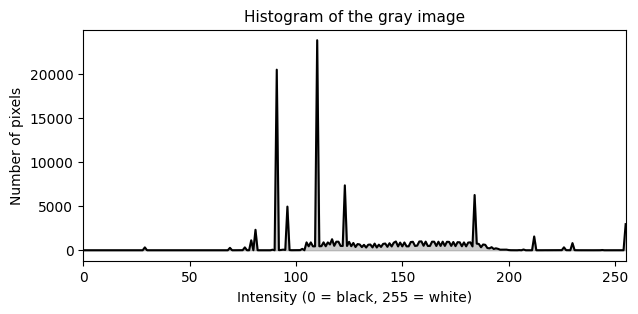

In [24]:
gray_small = cv2.cvtColor(base, cv2.COLOR_BGR2GRAY)

hist = cv2.calcHist([gray_small], [0], None, [256], [0, 256])     # histogram of the gray image

print("hist shape:", hist.shape, " ← 256 counts, one per intensity")
print("total counted pixels:", int(hist.sum()), " = height × width =", gray_small.size)
print("number of pixels with value 0 :", int(hist[0]))
print("number of pixels with value 128:", int(hist[128]))

plt.figure(figsize=(7, 3))
plt.plot(hist, color="black"); plt.fill_between(range(256), hist.ravel(), color="gray", alpha=0.4)
plt.xlabel("Intensity (0 = black, 255 = white)"); plt.ylabel("Number of pixels"); plt.xlim(0, 255)
plt.title("Histogram of the gray image"); plt.show()

### What happened? (parameters)
| Argument | Meaning |
|---|---|
| `[gray_small]` | A **list** of images (even if there is only one) |
| `[0]` | Which channel to use (0 for a grayscale image) |
| `None` | No mask — count all pixels a mask could restrict the counting to a region |
| `[256]` | Number of **bins** (groups) 256 = one bin per intensity |
| `[0, 256]` | Value range (upper limit is exclusive) |


In [25]:
def make_variants(g):
    f = g.astype(np.float32)
    return {
        "Normal":        g,
        "Dark":          (f * 0.35).astype(np.uint8),
        "Bright":        (255 - (255 - f) * 0.35).astype(np.uint8),
        "Low contrast":  (110 + f * 0.2).astype(np.uint8),
        "High contrast": np.clip((f - 128) * 2.5 + 128, 0, 255).astype(np.uint8),
    }

variants = make_variants(gray_small)

def histogram_lab(kind="Dark", bins=64):
    g = variants[kind]
    hist = cv2.calcHist([g], [0], None, [bins], [0, 256]).ravel()
    centres = (np.arange(bins) + 0.5) * 256 / bins
    fig, axs = plt.subplots(1, 2, figsize=(12, 3.6), gridspec_kw={"width_ratios": [1.2, 1.5]})
    axs[0].imshow(g, cmap="gray", vmin=0, vmax=255); axs[0].axis("off"); axs[0].set_title(kind)
    axs[1].bar(centres, hist, width=256 / bins, color="gray", edgecolor="black")
    axs[1].set_xlim(0, 255); axs[1].set_xlabel("Intensity (0 = black … 255 = white)"); axs[1].set_ylabel("Number of pixels")
    axs[1].set_title(f"mean={g.mean():.0f}   std={g.std():.0f}   min={g.min()}   max={g.max()}")
    plt.tight_layout(); plt.show()

interact(histogram_lab,
         kind=Dropdown(options=list(variants.keys()), value="Dark", description="Image"),
         bins=Dropdown(options=[8, 16, 32, 64, 128, 256], value=64, description="Bins"));

interactive(children=(Dropdown(description='Image', index=1, options=('Normal', 'Dark', 'Bright', 'Low contras…

### What happened?
* **Dark:** all mass on the left — the right side of the axis is empty.
* **Bright:** mirror image — mass on the right.
* **Low contrast:** a narrow peak — pixel values are all similar.
* **High contrast:** spikes at both ends (clipped blacks and whites).
* `mean` ≈ brightness, `std` ≈ contrast.

### 💡 An important idea: a histogram forgets position
We shuffle all the pixels randomly & The picture becomes noise but the histogram is **exactly the same**

**rng = np.random.default_rng(0):**

Creates a random number generator. The (0) is a seed ensuring that if you run this code multiple times it will shuffle the pixels in the exact same "random" order every time

**flat = gray_small.ravel().copy():**

Takes the 2D image matrix and flattens it into a single, long 1D list of pixel values. The .copy() ensures you are modifying a new list not the original image data

**rng.shuffle(flat):**

 Randomly scrambles the order of all the pixel values in that 1D list

**shuffled = flat.reshape(gray_small.shape):**

Takes the scrambled 1D list and folds it back into a 2D matrix matching the original image's dimensions

**The Result:**

The new shuffled image will look like complete visual noise (TV static). However because you only moved the pixels around without changing their actual values the histogram of shuffled will be exactly identical to the histogram of gray_small

Identical histograms? True


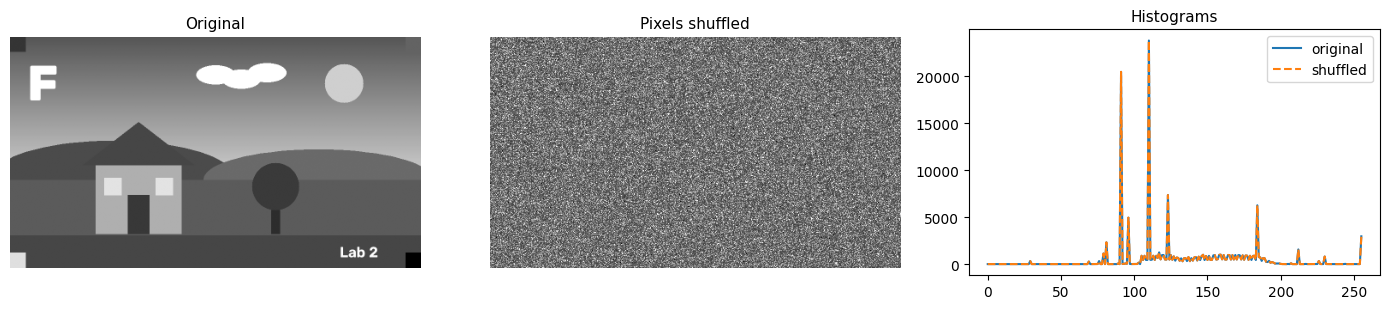

In [26]:
# This code takes all the pixels in your image scrambles their locations randomly and puts them back into a new image of the exact same size

rng = np.random.default_rng(0)
flat = gray_small.ravel().copy()
rng.shuffle(flat)                                     # random order of the SAME pixel values
shuffled = flat.reshape(gray_small.shape)

h1 = cv2.calcHist([gray_small], [0], None, [256], [0, 256])
h2 = cv2.calcHist([shuffled],   [0], None, [256], [0, 256])
print("Identical histograms?", np.array_equal(h1, h2))

fig, axs = plt.subplots(1, 3, figsize=(14, 3.2))
axs[0].imshow(gray_small, cmap="gray"); axs[0].set_title("Original"); axs[0].axis("off")
axs[1].imshow(shuffled, cmap="gray");  axs[1].set_title("Pixels shuffled"); axs[1].axis("off")
axs[2].plot(h1, label="original"); axs[2].plot(h2, "--", label="shuffled"); axs[2].legend(); axs[2].set_title("Histograms")
plt.tight_layout(); plt.show()

### 🔎 Colour images
Each channel has its own histogram (Same idea, just one `calcHist` call per channel)

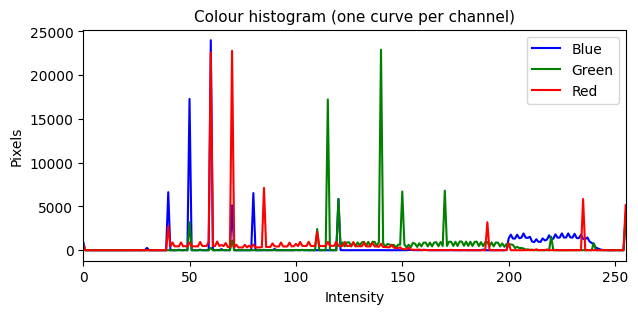

In [27]:
plt.figure(figsize=(7, 3))
for ch, name in enumerate(["Blue", "Green", "Red"]):
    h = cv2.calcHist([base], [ch], None, [256], [0, 256])
    plt.plot(h, color=name.lower(), label=name)
plt.legend(); plt.xlim(0, 255); plt.xlabel("Intensity"); plt.ylabel("Pixels"); plt.title("Colour histogram (one curve per channel)")
plt.show()

#  PART 18 — Histogram Equalization

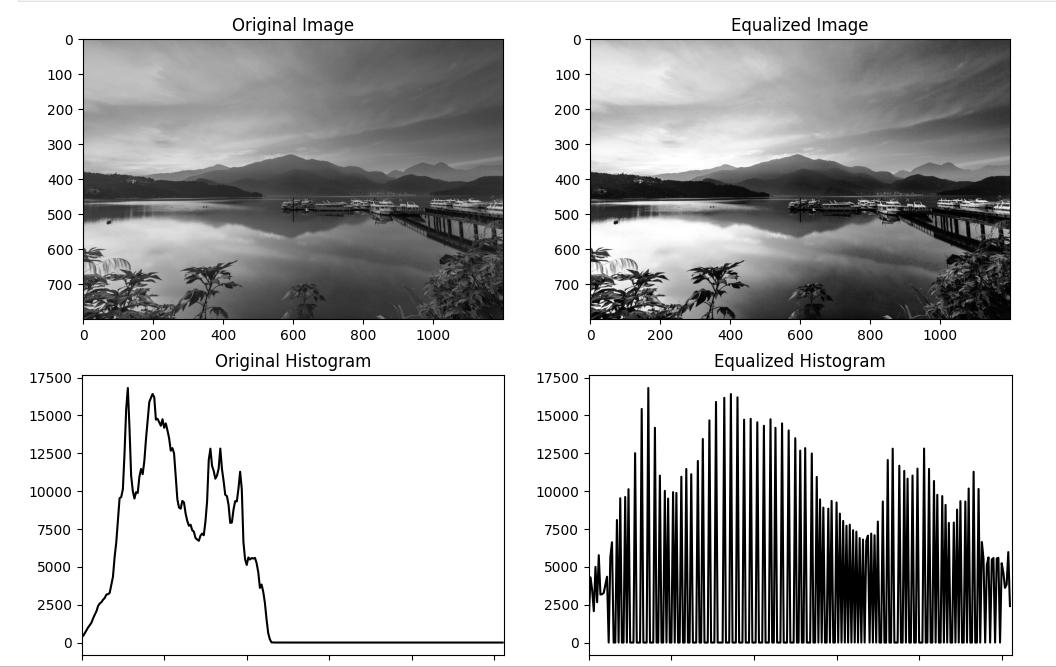

Histogram Equalization is an image enhancement technique used to improve image contrast by redistributing pixel intensity values

### What is the problem?
> **What if an image uses only a small portion of the available intensity range?**

A foggy photo might only use values between 100 and 160 out of the 256 available. Detail is hidden because the differences are tiny

**Histogram equalization** *spreads* the used intensities over the full range 0–255 so detail becomes visible

### **Why is this important?**
It's a fast, automatic way to improve contrast without choosing `alpha` and `beta` yourself

### **Real-world application**
X-ray and microscope images, night-vision cameras, preprocessing of faces or road scenes before analysis

### **Visual intuition — how it works**
1. Count how many pixels have each intensity (histogram)
2. Add the counts up from dark to bright: the **cumulative distribution (CDF)**
3. Use the CDF as the *mapping curve*: intensities where many pixels live get **stretched apart** and rarely used intensities get squeezed


In [28]:
tiny = np.array([[52, 55, 61, 59],
                 [79, 61, 76, 61],
                 [62, 59, 55, 104],
                 [63, 65, 66, 113]], dtype=np.uint8)

hist = np.bincount(tiny.ravel(), minlength=256)          # how many pixels of each value
cdf = hist.cumsum()                                      # running total
cdf_min = cdf[cdf > 0].min()
N = tiny.size

mapping = np.round((cdf - cdf_min) / (N - cdf_min) * 255).astype(np.uint8)   # the equalization formula
manual = mapping[tiny]                                   # apply the mapping to each pixel
opencv = cv2.equalizeHist(tiny)

print("Original:\n", tiny)
print("\nEqualized by hand:\n", manual)
print("\nEqualized by OpenCV:\n", opencv)
print("\nSame result?", np.array_equal(manual, opencv))

Original:
 [[ 52  55  61  59]
 [ 79  61  76  61]
 [ 62  59  55 104]
 [ 63  65  66 113]]

Equalized by hand:
 [[  0  34 119  68]
 [221 119 204 119]
 [136  68  34 238]
 [153 170 187 255]]

Equalized by OpenCV:
 [[  0  34 119  68]
 [221 119 204 119]
 [136  68  34 238]
 [153 170 187 255]]

Same result? True


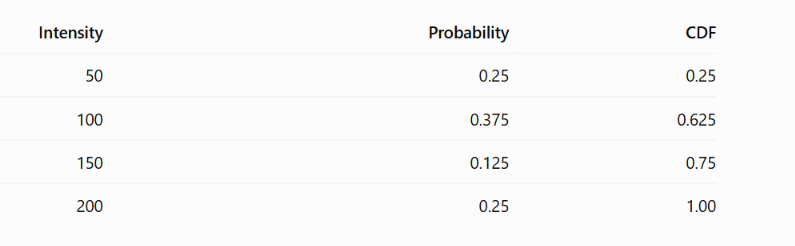

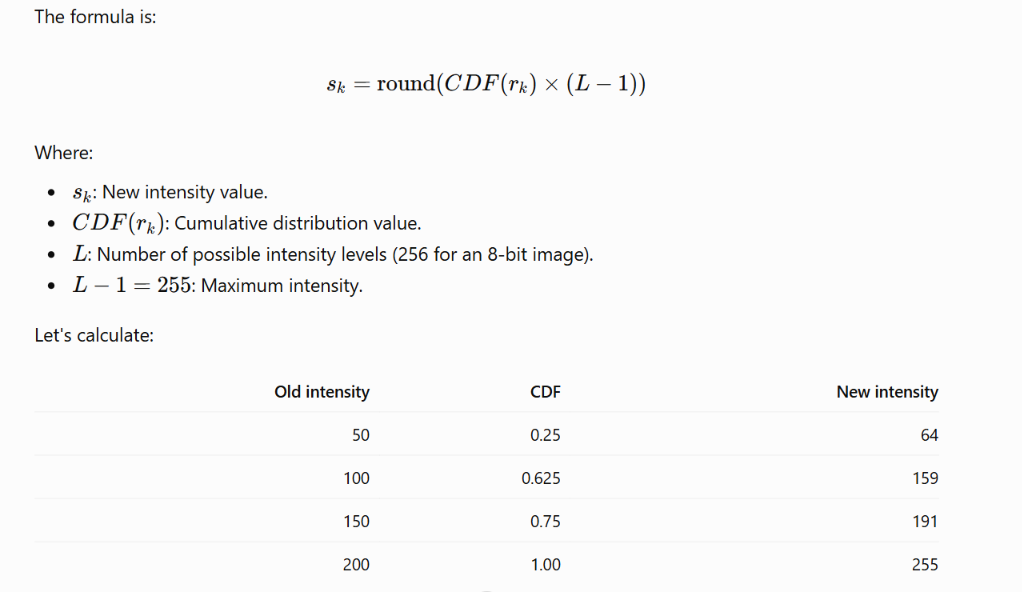

### 💻 Code
```python
equalized = cv2.equalizeHist(gray)         # works ONLY on single-channel uint8 images as Histogram equalization works on one intensity histogram
```

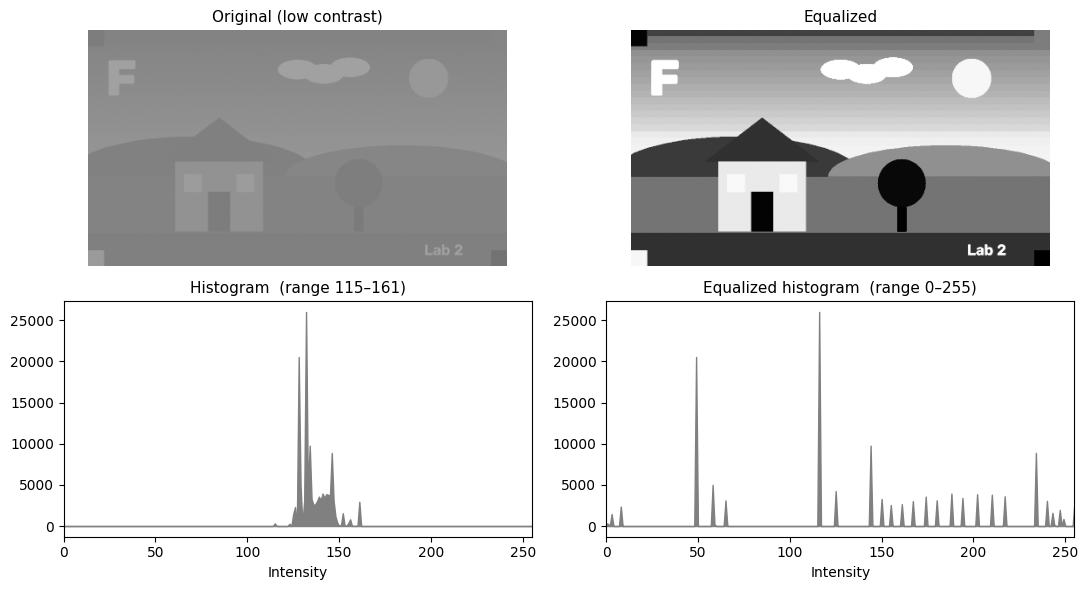

In [29]:
low = make_variants(gray_small)["Low contrast"]
equalized = cv2.equalizeHist(low)

fig, axs = plt.subplots(2, 2, figsize=(11, 6))
for col, (im, name) in enumerate([(low, "Original (low contrast)"), (equalized, "Equalized")]):
    axs[0, col].imshow(im, cmap="gray", vmin=0, vmax=255); axs[0, col].set_title(name); axs[0, col].axis("off")
    hh = cv2.calcHist([im], [0], None, [256], [0, 256]).ravel()
    axs[1, col].fill_between(range(256), hh, color="gray"); axs[1, col].set_xlim(0, 255)
    axs[1, col].set_title(f"{'Histogram' if col == 0 else 'Equalized histogram'}  (range {im.min()}–{im.max()})")
    axs[1, col].set_xlabel("Intensity")
plt.tight_layout(); plt.show()

### 🎮 Interactive Experiment — How squeezed can the image be?
Choose the range `[low … high]` that the image is compressed into, then equalize it. Notice the **comb-shaped** equalized histogram: only the original few levels exist, now spread apart: equalization cannot create information, it only redistributes it.

In [30]:
def equalization_lab(range_=(100, 150)):
    lo, hi = range_
    squeezed = (lo + gray_small.astype(np.float32) * (hi - lo) / 255).astype(np.uint8)
    eq = cv2.equalizeHist(squeezed)
    fig, axs = plt.subplots(2, 2, figsize=(11, 5.8))
    for col, (im, name) in enumerate([(squeezed, f"Input (values {squeezed.min()}–{squeezed.max()})"), (eq, "After equalizeHist")]):
        axs[0, col].imshow(im, cmap="gray", vmin=0, vmax=255); axs[0, col].set_title(name); axs[0, col].axis("off")
        hh = cv2.calcHist([im], [0], None, [256], [0, 256]).ravel()
        axs[1, col].bar(range(256), hh, width=1.0, color="gray"); axs[1, col].set_xlim(0, 255); axs[1, col].set_xlabel("Intensity")
        axs[1, col].set_title(f"{len(np.unique(im))} different gray levels used")
    plt.tight_layout(); plt.show()

interact(equalization_lab, range_=IntRangeSlider(value=(100, 150), min=0, max=255, step=5, description="Used range", continuous_update=False));

interactive(children=(IntRangeSlider(value=(100, 150), continuous_update=False, description='Used range', max=…

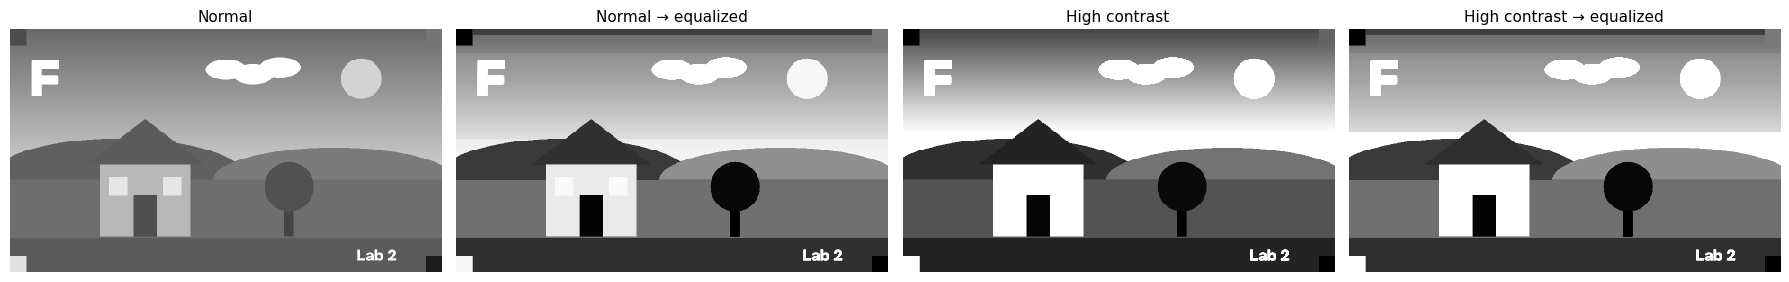

In [31]:
good = variants["Normal"]
high = variants["High contrast"]
show_row([good, cv2.equalizeHist(good), high, cv2.equalizeHist(high)],
         ["Normal", "Normal → equalized", "High contrast", "High contrast → equalized"], figsize=(18, 3.2), axis=False)

# **What about Histogram Equalization for color images?**



A common approach is:

Y   → Brightness / luminance

Cr  → Red-related color information

Cb  → Blue-related color information

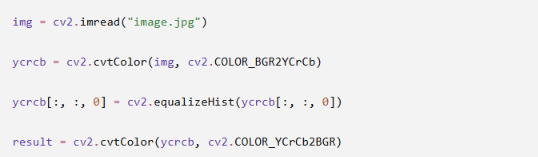

Here we equalize only the Y channel which represents brightness while keeping the color information (Cr, Cb) unchanged





# PART 19 — Normalization

### What is the problem?
> "My neural network learns badly when the inputs are numbers like 0…255 Why do tutorials always divide by 255?"

Machine-learning models train best when inputs are **small and consistently scaled**

 **Normalization** rescales pixel values into a convenient range.



###  Normalization is **not** the same as histogram equalization
* **Normalization** changes the *numbers' scale* (a linear rescale) The *shape* of the histogram stays the same

* **Equalization** changes the *shape* of the histogram (a non-linear redistribution) to improve contrast



In [32]:
patch_u8 = base[100:103, 200:203, 0]                             # a 3x3 patch from the blue channel
patch_f  = patch_u8.astype(np.float32) / 255.0                   # step 1: float, step 2: divide by 255

print("uint8 (0–255):\n", patch_u8)
print("\nfloat32 (0–1):\n", patch_f.round(3))
print("\ndtype before:", patch_u8.dtype, " after:", patch_f.dtype)

img_f = base.astype(np.float32) / 255.0
print("\nWhole image: min", img_f.min(), " max", img_f.max(), " dtype", img_f.dtype)

# Min–Max normalization: stretch THIS image's own min..max onto 0..1
lowc = variants["Low contrast"]
mm = cv2.normalize(lowc, None, alpha=0, beta=1, norm_type=cv2.NORM_MINMAX, dtype=cv2.CV_32F)
print(f"\nLow-contrast image range {lowc.min()}–{lowc.max()}  →  min–max normalized range {mm.min()} – {mm.max()}")

# Standardization: mean 0, std 1
std_img = (img_f - img_f.mean()) / img_f.std()
print(f"Standardized: mean ≈ {std_img.mean():.3f}, std ≈ {std_img.std():.3f}")

uint8 (0–255):
 [[230 230 230]
 [230 230 230]
 [230 230 230]]

float32 (0–1):
 [[0.902 0.902 0.902]
 [0.902 0.902 0.902]
 [0.902 0.902 0.902]]

dtype before: uint8  after: float32

Whole image: min 0.0  max 1.0  dtype float32

Low-contrast image range 115–161  →  min–max normalized range 4.6566128730773926e-08 – 1.0000001192092896
Standardized: mean ≈ 0.000, std ≈ 1.000


### What happened? (line by line)
| Code | Meaning |
|---|---|
| `.astype(np.float32)` | Convert to decimal numbers first: integer division would give 0 |
| `/ 255.0` | The fixed maximum of `uint8`: 255 → 1.0, 0 → 0.0 |
| `cv2.normalize(src, None, 0, 1, cv2.NORM_MINMAX, dtype=cv2.CV_32F)` | Linearly map this image's smallest value to `0` and its largest to `1` |
| `(x − mean) / std` | Standardization — typical for pretrained models (e.g. subtract channel means) |


In [33]:
def normalization_lab(method="÷255 (fixed 0–1)"):
    src = variants["Low contrast"]
    f = src.astype(np.float32)
    if method == "Original (0–255)":
        arr = src
    elif method == "÷255 (fixed 0–1)":
        arr = f / 255.0
    elif method == "Min–Max → 0–1":
        arr = cv2.normalize(src, None, 0, 1, cv2.NORM_MINMAX, dtype=cv2.CV_32F)
    elif method == "Min–Max → 0–255 (contrast stretch)":
        arr = cv2.normalize(src, None, 0, 255, cv2.NORM_MINMAX)
    elif method == "Standardize (mean 0, std 1)":
        arr = (f - f.mean()) / f.std()
    else:
        arr = cv2.equalizeHist(src)

    if arr.dtype == np.uint8:               vmin, vmax = 0, 255
    elif "Standardize" in method:           vmin, vmax = arr.min(), arr.max()
    else:                                   vmin, vmax = 0, 1
    fig, axs = plt.subplots(1, 2, figsize=(11, 3.4))
    axs[0].imshow(arr, cmap="gray", vmin=vmin, vmax=vmax); axs[0].axis("off")
    axs[0].set_title(f"{method}   dtype={arr.dtype}")
    axs[1].hist(arr.ravel(), bins=60, color="gray")
    axs[1].set_title(f"min={arr.min():.2f}  max={arr.max():.2f}  mean={arr.mean():.2f}  std={arr.std():.2f}")
    axs[1].set_xlabel("value"); axs[1].set_ylabel("pixels")
    plt.tight_layout(); plt.show()

interact(normalization_lab,
         method=Dropdown(options=["Original (0–255)", "÷255 (fixed 0–1)", "Min–Max → 0–1", "Min–Max → 0–255 (contrast stretch)",
                                  "Standardize (mean 0, std 1)", "Histogram equalization (for comparison)"],
                         value="÷255 (fixed 0–1)", description="Method"));

interactive(children=(Dropdown(description='Method', index=1, options=('Original (0–255)', '÷255 (fixed 0–1)',…

### 🔎 What happened?
* **÷255:** the picture looks *exactly* the same (still low contrast) Only the numbers changed (0–255 → 0–1). The histogram **shape** is identical

* **Min–Max:** the low-contrast image now uses its entire range — this *linear* stretch is called **contrast stretching**

* **Standardize:** values centred at 0 (some negative) Not displayable as a normal image

* **Equalization:** the histogram **shape** is changed (flattened) That's a different idea


**Division by 255 (img / 255.0) - Fixed Scaling:**

* It divides every pixel value by the constant 255 (the theoretical maximum of an 8-bit image)

* It simply converts the scale from [0, 255] to [0.0, 1.0]. If your original image was dark and its highest pixel value was only 100 the new maximum value will be about 0.39

* It does not change the contrast or brightness of the image; it only changes the data scale



**Min-Max Normalization (cv2.normalize with NORM_MINMAX) - Dynamic Stretching:**

* It looks at the actual data in your specific image, finds the absolute darkest pixel (min) and brightest pixel (max), and stretches them using the formula: (pixel - min) / (max - min)

* The darkest pixel is forced to become exactly 0.0, and the brightest pixel is forced to become exactly 1.0, regardless of what their original values were

* This actively alters the image's contrast by stretching the pixel values to fill the entire available range


**Which one has an identical histogram shape?**

Division by 255 has the identical histogram shape Because dividing by 255 is a fixed global scale the relative clustering and position of the pixels remain exactly the same—the x-axis simply changes its labels from 0 - 255 to 0.0 - 1.0

Min-Max normalization on the other hand shifts and stretches the histogram If your original histogram was tightly clustered in the middle (low contrast) Min-Max will pull it apart so it spans all the way from the left edge (0.0) to the right edge (1.0), changing its visual width and footprint